In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("output.csv")

In [4]:
df.head(10)


,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
5,Now I am getting angry and I want my damn pho.,0
6,Honeslty it didn't taste THAT fresh.),0
7,The potatoes were like rubber and you could te...,0
8,The fries were great too.,1
9,A great touch.,1


In [5]:
df.tail()

,Review,Liked
995,I think food should have flavor and texture an...,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go b...,0
998,"The whole experience was underwhelming, and I ...",0
999,"Then, as if I hadn't wasted enough of my life ...",0


In [6]:
df.shape

(1000, 2)

In [7]:
df.columns

Index([' Review', 'Liked'], dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0    Review  1000 non-null   str  
 1   Liked    1000 non-null   int64
dtypes: int64(1), str(1)
memory usage: 72.7 KB


In [9]:
df.describe()

,Liked
count,1000.00000
mean,0.50000
std,0.50025
min,0.00000
25%,0.00000
50%,0.50000
75%,1.00000
max,1.00000


In [16]:
df.columns = df.columns.str.strip()

df.columns

Index(['Review', 'Liked'], dtype='str')

In [17]:
df['Liked'].value_counts()

Liked
1    500
0    500
Name: count, dtype: int64

In [18]:
df['Liked'].value_counts(normalize=True) * 100

Liked
1    50.0
0    50.0
Name: proportion, dtype: float64

In [19]:
df.isnull().sum()

Review    0
Liked     0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(4)

In [21]:
df['Length'] = df['Review'].astype(str).apply(len)

df[['Review', 'Length']].head()

,Review,Length
0,Wow... Loved this place.,24
1,Crust is not good.,18
2,Not tasty and the texture was just nasty.,41
3,Stopped by during the late May bank holiday of...,87
4,The selection on the menu was great and so wer...,59


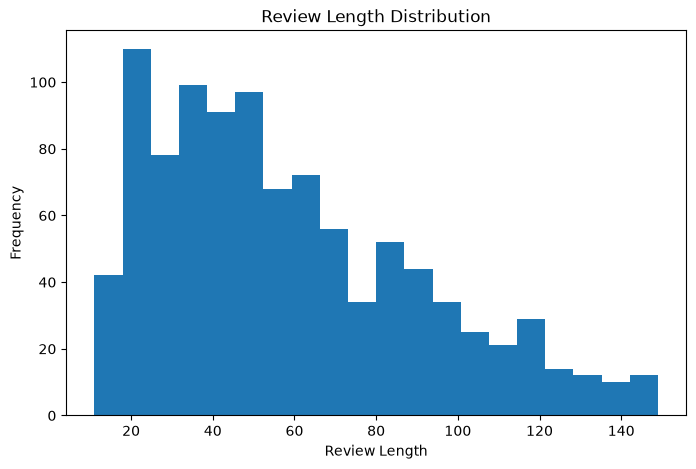

In [22]:
plt.figure(figsize=(8, 5))
plt.hist(df['Length'], bins=20)
plt.title('Review Length Distribution')
plt.xlabel('Review Length')
plt.ylabel('Frequency')
plt.show()

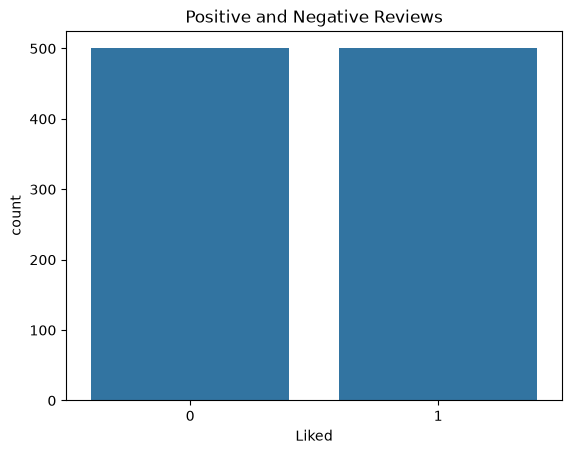

In [23]:
sns.countplot(x='Liked', data=df)
plt.title('Positive and Negative Reviews')
plt.show()

In [24]:
import re
import nltk
import string

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Prasanna\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Prasanna\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Prasanna\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [25]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Preserve important negative words
stop_words = stop_words - {'not', 'no', 'nor'}

In [26]:
df['Clean_Review'] = df['Review'].str.lower()

df[['Review', 'Clean_Review']].head()

,Review,Clean_Review
0,Wow... Loved this place.,wow... loved this place.
1,Crust is not good.,crust is not good.
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty.
3,Stopped by during the late May bank holiday of...,stopped by during the late may bank holiday of...
4,The selection on the menu was great and so wer...,the selection on the menu was great and so wer...


In [27]:
df['Clean_Review'] = df['Clean_Review'].apply(
    lambda x: x.translate(str.maketrans('', '', string.punctuation))
)

In [28]:
df['Clean_Review'] = df['Clean_Review'].apply(
    lambda x: re.sub(r'[^a-zA-Z\s]', '', x)
)

In [29]:
df['Clean_Review'] = df['Clean_Review'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

In [30]:
df['Clean_Review'] = df['Clean_Review'].apply(
    lambda x: ' '.join(
        word for word in x.split() if word not in stop_words
    )
)

In [31]:
from nltk.stem import PorterStemmer

ps = PorterStemmer()

df['Clean_Review'] = df['Clean_Review'].apply(
    lambda x: ' '.join(ps.stem(word) for word in x.split())
)

In [32]:
df[['Review', 'Clean_Review']].head(10)

,Review,Clean_Review
0,Wow... Loved this place.,wow love place
1,Crust is not good.,crust not good
2,Not tasty and the texture was just nasty.,not tasti textur nasti
3,Stopped by during the late May bank holiday of...,stop late may bank holiday rick steve recommen...
4,The selection on the menu was great and so wer...,select menu great price
5,Now I am getting angry and I want my damn pho.,get angri want damn pho
6,Honeslty it didn't taste THAT fresh.),honeslti didnt tast fresh
7,The potatoes were like rubber and you could te...,potato like rubber could tell made ahead time ...
8,The fries were great too.,fri great
9,A great touch.,great touch


In [33]:
X = df['Clean_Review']
y = df['Liked']

In [34]:
print(X.head())
print(y.head())

0                                       wow love place
1                                       crust not good
2                               not tasti textur nasti
3    stop late may bank holiday rick steve recommen...
4                              select menu great price
Name: Clean_Review, dtype: str
0    1
1    0
2    0
3    1
4    1
Name: Liked, dtype: int64


In [35]:
from sklearn.model_selection import train_test_split

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [37]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800,)
X_test: (200,)
y_train: (800,)
y_test: (200,)


In [38]:
from sklearn.feature_extraction.text import CountVectorizer

In [39]:
cv = CountVectorizer(max_features=1500)

In [40]:
X_train_cv = cv.fit_transform(X_train)

In [41]:
X_test_cv = cv.transform(X_test)

In [42]:
print("X_train_cv:", X_train_cv.shape)
print("X_test_cv:", X_test_cv.shape)

X_train_cv: (800, 1414)
X_test_cv: (200, 1414)


In [43]:
print(cv.get_feature_names_out()[:20])

['absolut' 'absolutley' 'accomod' 'accordingli' 'account' 'ach'
 'acknowledg' 'across' 'actual' 'ad' 'afford' 'afternoon' 'ago' 'ahead'
 'airlin' 'airport' 'ala' 'albondiga' 'allergi' 'almost']


In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [45]:
tfidf = TfidfVectorizer(max_features=1500)

In [46]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [47]:
X_test_tfidf = tfidf.transform(X_test)

In [48]:
print("X_train_tfidf:", X_train_tfidf.shape)
print("X_test_tfidf:", X_test_tfidf.shape)

X_train_tfidf: (800, 1414)
X_test_tfidf: (200, 1414)


In [49]:
print(tfidf.get_feature_names_out()[:20])

['absolut' 'absolutley' 'accomod' 'accordingli' 'account' 'ach'
 'acknowledg' 'across' 'actual' 'ad' 'afford' 'afternoon' 'ago' 'ahead'
 'airlin' 'airport' 'ala' 'albondiga' 'allergi' 'almost']


In [50]:
from sklearn.naive_bayes import MultinomialNB

In [51]:
model1 = MultinomialNB()

In [52]:
model1.fit(X_train_cv, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[400.,400.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 1414)","[[3.,0.,0.,...,0.,1.,4.], [6.,1.,1.,...,1.,3.,0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 1414)","[[-6.86,-8.25,-8.25,...,-8.25,-7.55,-6.64], [-6.25,-7.5 ,-7.5 ,...,-7.5 ,-6.81,-8.19]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1414


In [53]:
y_pred1 = model1.predict(X_test_cv)

In [54]:
print(y_pred1)

[1 0 0 1 1 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 1 1 1 0 0 1 0 1 0 1 1 0 0
 0 0 0 0 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 1 1 1 1 0 1 1 1 0 0 0 1 1 1
 1 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 1 1 0 0 0 1 0 1 0 1 1 0 1 0 1 0 1 0 1 1
 1 0 0 1 1 1 1 1 0 0 1 0 1 0 0 0 1 0 0 1 0 0 1 0 0 0 0 1 0 1 1 1 0 1 0 0 1
 1 0 1 1 1 1 0 0 1 1 0 0 1 1 1 0 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0 0 1
 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1]


In [55]:
from sklearn.metrics import accuracy_score

accuracy1 = accuracy_score(y_test, y_pred1)

print("MultinomialNB + CountVectorizer Accuracy:", accuracy1 * 100)

MultinomialNB + CountVectorizer Accuracy: 81.5


In [56]:
model2 = MultinomialNB()

In [57]:
model2.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[400.,400.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 1414)","[[0.79,0. ,0. ,...,0. ,0.28,1.4 ], [3.11,0.79,0.47,...,0.33,1.39,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 1414)","[[-7.17,-7.75,-7.75,...,-7.75,-7.5 ,-6.87], [-6.32,-7.16,-7.35,...,-7.45,-6.86,-7.74]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1414


In [58]:
y_pred2 = model2.predict(X_test_tfidf)

In [59]:
accuracy2 = accuracy_score(y_test, y_pred2)

print("MultinomialNB + TF-IDF Accuracy:", accuracy2 * 100)

MultinomialNB + TF-IDF Accuracy: 79.5


In [60]:
print(y_pred2)

[1 0 0 1 1 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 1 1 1 0 0 1 0 1 0 1 1 0 0
 0 0 0 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 0 0 0 0 0 1 1 1 1 0 1 1 1 0 0 0 1 1 1
 1 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 0 1 1 0 0 0 1 0 1 0 1 1 0 1 0 1 1 1 0 1 1
 1 0 0 1 1 1 1 0 0 0 1 0 1 0 0 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 1 0 1 0 0 1
 1 0 1 1 1 1 0 0 1 1 0 0 1 1 1 0 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0 0 1
 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1]


In [61]:
from sklearn.naive_bayes import BernoulliNB

In [62]:
binary_vectorizer = CountVectorizer(
    max_features=1500,
    binary=True
)

In [63]:
X_train_binary = binary_vectorizer.fit_transform(X_train)
X_test_binary = binary_vectorizer.transform(X_test)

In [64]:
model3 = BernoulliNB()

model3.fit(X_train_binary, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[400.,400.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 1414)","[[3.,0.,0.,...,0.,1.,3.], [6.,1.,1.,...,1.,3.,0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 1414)","[[-4.61,-6. ,-6. ,...,-6. ,-5.3 ,-4.61], [-4.05,-5.3 ,-5.3 ,...,-5.3 ,-4.61,-6. ]]"


In [65]:
y_pred3 = model3.predict(X_test_binary)

In [66]:
accuracy3 = accuracy_score(y_test, y_pred3)

print("BernoulliNB + Binary Features Accuracy:", accuracy3 * 100)

BernoulliNB + Binary Features Accuracy: 81.0


In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [68]:
print("MODEL 1: MultinomialNB + CountVectorizer")

print("Accuracy:", accuracy_score(y_test, y_pred1))
print("Precision:", precision_score(y_test, y_pred1))
print("Recall:", recall_score(y_test, y_pred1))
print("F1 Score:", f1_score(y_test, y_pred1))

print("\nClassification Report:")
print(classification_report(y_test, y_pred1))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred1))

MODEL 1: MultinomialNB + CountVectorizer
Accuracy: 0.815
Precision: 0.8118811881188119
Recall: 0.82
F1 Score: 0.8159203980099502

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.81      0.81       100
           1       0.81      0.82      0.82       100

    accuracy                           0.81       200
   macro avg       0.82      0.81      0.81       200
weighted avg       0.82      0.81      0.81       200

Confusion Matrix:
[[81 19]
 [18 82]]


In [69]:
print("MODEL 2: MultinomialNB + TF-IDF")

print("Accuracy:", accuracy_score(y_test, y_pred2))
print("Precision:", precision_score(y_test, y_pred2))
print("Recall:", recall_score(y_test, y_pred2))
print("F1 Score:", f1_score(y_test, y_pred2))

print("\nClassification Report:")
print(classification_report(y_test, y_pred2))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred2))

MODEL 2: MultinomialNB + TF-IDF
Accuracy: 0.795
Precision: 0.780952380952381
Recall: 0.82
F1 Score: 0.8

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.77      0.79       100
           1       0.78      0.82      0.80       100

    accuracy                           0.80       200
   macro avg       0.80      0.79      0.79       200
weighted avg       0.80      0.80      0.79       200

Confusion Matrix:
[[77 23]
 [18 82]]


In [70]:
print("MODEL 3: BernoulliNB + Binary Features")

print("Accuracy:", accuracy_score(y_test, y_pred3))
print("Precision:", precision_score(y_test, y_pred3))
print("Recall:", recall_score(y_test, y_pred3))
print("F1 Score:", f1_score(y_test, y_pred3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred3))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred3))

MODEL 3: BernoulliNB + Binary Features
Accuracy: 0.81
Precision: 0.7870370370370371
Recall: 0.85
F1 Score: 0.8173076923076923

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.77      0.80       100
           1       0.79      0.85      0.82       100

    accuracy                           0.81       200
   macro avg       0.81      0.81      0.81       200
weighted avg       0.81      0.81      0.81       200

Confusion Matrix:
[[77 23]
 [15 85]]


In [71]:
models = {
    "MultinomialNB + CountVectorizer": y_pred1,
    "MultinomialNB + TF-IDF": y_pred2,
    "BernoulliNB + Binary Features": y_pred3
}

for name, pred in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))


 MultinomialNB + CountVectorizer
Accuracy: 0.815
Precision: 0.8118811881188119
Recall: 0.82
F1 Score: 0.8159203980099502

 MultinomialNB + TF-IDF
Accuracy: 0.795
Precision: 0.780952380952381
Recall: 0.82
F1 Score: 0.8

 BernoulliNB + Binary Features
Accuracy: 0.81
Precision: 0.7870370370370371
Recall: 0.85
F1 Score: 0.8173076923076923


In [72]:
new_reviews = [
    "The food was fantastic and the service was excellent.",
    "Worst service ever. The food was terrible.",
    "The restaurant has a beautiful ambience.",
    "I will never visit this restaurant again.",
    "The experience was average and nothing special."
]

In [73]:
def preprocess_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    words = text.split()
    words = [word for word in words if word not in stop_words]
    words = [ps.stem(word) for word in words]
    return ' '.join(words)

cleaned_reviews = [preprocess_text(review) for review in new_reviews]

In [74]:
new_reviews_vector = cv.transform(cleaned_reviews)

In [75]:
predictions = model1.predict(new_reviews_vector)

for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print()

Review: The food was fantastic and the service was excellent.
Predicted Sentiment: Positive

Review: Worst service ever. The food was terrible.
Predicted Sentiment: Negative

Review: The restaurant has a beautiful ambience.
Predicted Sentiment: Positive

Review: I will never visit this restaurant again.
Predicted Sentiment: Positive

Review: The experience was average and nothing special.
Predicted Sentiment: Negative



In [76]:
probabilities = model1.predict_proba(new_reviews_vector)

for review, prob in zip(new_reviews, probabilities):
    print("Review:", review)
    print("Negative Probability:", round(prob[0] * 100, 2), "%")
    print("Positive Probability:", round(prob[1] * 100, 2), "%")
    print()

Review: The food was fantastic and the service was excellent.
Negative Probability: 0.89 %
Positive Probability: 99.11 %

Review: Worst service ever. The food was terrible.
Negative Probability: 98.85 %
Positive Probability: 1.15 %

Review: The restaurant has a beautiful ambience.
Negative Probability: 3.51 %
Positive Probability: 96.49 %

Review: I will never visit this restaurant again.
Negative Probability: 37.05 %
Positive Probability: 62.95 %

Review: The experience was average and nothing special.
Negative Probability: 87.37 %
Positive Probability: 12.63 %



In [77]:
import joblib

In [78]:
joblib.dump(model1, 'naive_bayes_model.pkl')

['naive_bayes_model.pkl']

In [79]:
joblib.dump(cv, 'count_vectorizer.pkl')

['count_vectorizer.pkl']

In [80]:
joblib.dump(
    {'stop_words': stop_words},
    'preprocessing.pkl'
)

['preprocessing.pkl']

In [82]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'count_vectorizer.pkl', 'naive_bayes_model.ipynb', 'naive_bayes_model.pkl', 'output.csv', 'preprocessing.pkl']
